# CHB-MIT: full overlapping-window PE/WPE/MPE trajectories across five EEG bands and three states

This notebook preserves **every valid overlapping window** (10-second window, 5-second step) for **interictal, preictal, and ictal** data. It does not replace the trajectories with state averages. Each row in the raw feature file corresponds to a patient × EDF × channel × window × band, with PE, WPE, and MPE at scales 1–5.

It supports within-patient, seizure-by-seizure trajectory inspection and cross-patient overlays of individual trajectories. State averages are optional descriptive summaries only; they are not the main trajectory analysis. Interictal windows remain ordered by their own EDF-local time because they do not have a genuine seizure-onset reference.

**Resumability:** per-channel/per-band checkpoints are saved to Google Drive. If runtime stops, rerun setup/discovery/parser cells and the processing cell to reuse completed chunks. Checkpoints protect saved progress but cannot themselves force Colab to keep running after browser closure; that depends on account/runtime background-execution support.

**Caution:** overlapping windows are correlated. Do not treat every window as an independent sample for inferential statistics. Verify seizure annotations, channel montage consistency, and interictal baseline eligibility before publication.

## 1. Mount Drive and set paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import re, math, warnings, gc
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from scipy.stats import wilcoxon

DATA_ROOT = Path('/content/drive/MyDrive/chbmit/1.0.0')
OUTPUT_DIR = Path('/content/drive/MyDrive/chbmit/entropy_frequency_band_results_overlapping_allbands_v3')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 10
STEP_SECONDS = 5  # 50% overlap
PREICTAL_MINUTES = 45
EMBEDDING_DIM = 3
TIME_DELAY = 1
MPE_SCALES = [1, 2, 3, 4, 5]
FILTER_ORDER = 4
BANDS = {'delta': (0.5, 4.0), 'theta': (4.0, 8.0), 'alpha': (8.0, 13.0), 'beta': (13.0, 30.0), 'gamma': (30.0, 45.0)}

if not DATA_ROOT.exists():
    raise FileNotFoundError(f'Cannot find {DATA_ROOT}; verify the Drive folder path.')
print('Dataset root:', DATA_ROOT)
print('Outputs (separate beta/gamma run):', OUTPUT_DIR)
print('Bands to process:', BANDS)
print('Existing Version 1 results are not modified. This is a fresh, separate all-band run.')

Mounted at /content/drive
Dataset root: /content/drive/MyDrive/chbmit/1.0.0
Outputs: /content/drive/MyDrive/chbmit/entropy_frequency_band_results


## 2. Install MNE and discover EDF/summary files

In [ ]:
%pip -q install mne
import mne
mne.set_log_level('WARNING')
edf_files = sorted(p for p in DATA_ROOT.rglob('*') if p.is_file() and p.suffix.lower()=='.edf')
summary_files = sorted(p for p in DATA_ROOT.rglob('*summary*.txt') if p.is_file())
print('EDF files:', len(edf_files), '| summary files:', len(summary_files))
for p in edf_files[:10]: print(p.relative_to(DATA_ROOT))
if not edf_files: raise FileNotFoundError('No EDF files found under the configured root.')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
EDF files: 686 | summary files: 24
chb01/chb01_01.edf
chb01/chb01_02.edf
chb01/chb01_03.edf
chb01/chb01_04.edf
chb01/chb01_05.edf
chb01/chb01_06.edf
chb01/chb01_07.edf
chb01/chb01_08.edf
chb01/chb01_09.edf
chb01/chb01_10.edf


## 3. Parse CHB-MIT seizure summaries

The parser expects standard entries such as `File Name: chb01_03.edf`, `Seizure 1 Start Time: 2996 seconds`, and `Seizure 1 End Time: 3036 seconds`. Inspect the resulting event table.

In [ ]:
def parse_summaries(paths):
    events = {}
    for sp in paths:
        txt = sp.read_text(errors='ignore')
        current = None; starts = []; ends = []
        def flush():
            nonlocal current, starts, ends
            if current:
                pairs=[]
                for i, s in enumerate(starts):
                    if i < len(ends) and ends[i] >= s: pairs.append((float(s), float(ends[i])))
                events[Path(current).name.lower()] = pairs
            current=None; starts=[]; ends=[]
        for line in txt.splitlines():
            fm=re.search(r'File Name:\s*(\S+\.edf)', line, re.I)
            if fm:
                flush(); current=fm.group(1).strip(); continue
            sm=re.search(r'Seizure\s*\d*\s*Start Time:\s*(\d+(?:\.\d+)?)\s*seconds?', line, re.I)
            em=re.search(r'Seizure\s*\d*\s*End Time:\s*(\d+(?:\.\d+)?)\s*seconds?', line, re.I)
            if sm: starts.append(float(sm.group(1)))
            if em: ends.append(float(em.group(1)))
        flush()
    return events

seizure_events_by_file = parse_summaries(summary_files)
def patient_id_from_path(path):
    for part in [path.name] + [p.name for p in path.parents]:
        m=re.search(r'(chb\d+)', part, re.I)
        if m: return m.group(1).lower()
    return 'unknown'

event_rows=[]
for p in edf_files:
    for j,(s,e) in enumerate(seizure_events_by_file.get(p.name.lower(), []),1):
        event_rows.append({'patient_id':patient_id_from_path(p),'edf_file':str(p),'file_name':p.name,
                           'seizure_number_in_file':j,'seizure_start_sec':s,'seizure_end_sec':e})
events_df=pd.DataFrame(event_rows)
print('Parsed seizure events:',len(events_df))
display(events_df.head(15))

Parsed seizure events: 198


,patient_id,edf_file,file_name,seizure_number_in_file,seizure_start_sec,seizure_end_sec
0,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_03.edf,1,2996.0,3036.0
1,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_04.edf,1,1467.0,1494.0
2,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_15.edf,1,1732.0,1772.0
3,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_16.edf,1,1015.0,1066.0
4,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_18.edf,1,1720.0,1810.0
5,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_21.edf,1,327.0,420.0
6,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_26.edf,1,1862.0,1963.0
7,chb02,/content/drive/MyDrive/chbmit/1.0.0/chb02/chb0...,chb02_16+.edf,1,2972.0,3053.0
8,chb02,/content/drive/MyDrive/chbmit/1.0.0/chb02/chb0...,chb02_16.edf,1,130.0,212.0
9,chb02,/content/drive/MyDrive/chbmit/1.0.0/chb02/chb0...,chb02_19.edf,1,3369.0,3378.0


## 4. Entropy implementations

PE is normalized Shannon entropy over ordinal patterns. WPE weights each embedded pattern by the variance of its `m` samples; this explicit definition should be reported in the methods. MPE coarse-grains the signal by non-overlapping blocks at each scale and computes PE. Stable sorting provides deterministic handling of ties. Short/constant segments can return NaN.

In [ ]:
def ordinal_patterns(x, m=3, tau=1):
    x = np.asarray(x, dtype=float)
    n = len(x) - (m - 1) * tau
    if n <= 0:
        return np.empty((0, m), dtype=np.int16), np.empty((0, m), dtype=float)
    emb = np.column_stack([x[i*tau:i*tau+n] for i in range(m)])
    return np.argsort(emb, axis=1, kind='stable').astype(np.int16), emb

def _pattern_codes(patterns, m):
    # Each ordinal permutation is encoded as a base-m integer.
    powers = (m ** np.arange(patterns.shape[1]-1, -1, -1)).astype(np.int64)
    return patterns.astype(np.int64) @ powers

def entropy_from_patterns(patterns, weights=None, m=3):
    if len(patterns) == 0:
        return np.nan
    codes = _pattern_codes(patterns, m)
    n_possible = math.factorial(m)
    if weights is None:
        counts = np.bincount(codes, minlength=m**m).astype(float)
    else:
        weights = np.asarray(weights, dtype=float)
        valid = np.isfinite(weights) & (weights >= 0)
        codes, weights = codes[valid], weights[valid]
        if len(codes) == 0 or weights.sum() <= 0:
            return np.nan
        counts = np.bincount(codes, weights=weights, minlength=m**m).astype(float)
    # Only codes representing actual permutations can be non-zero.
    counts = counts[counts > 0]
    if len(counts) == 0 or counts.sum() <= 0:
        return np.nan
    probs = counts / counts.sum()
    return float(-np.sum(probs * np.log(probs)) / np.log(n_possible))

def PE(x, m=3, tau=1):
    patterns, _ = ordinal_patterns(x, m, tau)
    return entropy_from_patterns(patterns, None, m)

def WPE(x, m=3, tau=1):
    patterns, embedded = ordinal_patterns(x, m, tau)
    if not len(patterns):
        return np.nan
    # Explicit variance-weighted ordinal-pattern implementation.
    return entropy_from_patterns(patterns, np.var(embedded, axis=1), m)

def coarse_grain(x, scale):
    x = np.asarray(x, dtype=float)
    n = len(x) // scale
    return x[:n*scale].reshape(n, scale).mean(axis=1) if n else np.array([])

def MPE(x, scales=(1,2,3,4,5), m=3, tau=1):
    return {f'MPE_s{s}': PE(coarse_grain(x, s), m, tau) for s in scales}

# Quick consistency/sanity check. These are synthetic values, not dataset results.
rng = np.random.default_rng(7)
test = np.sin(np.linspace(0, 30*np.pi, 3000)) + 0.2*rng.normal(size=3000)
print('Synthetic signal sanity check:', {'PE': PE(test), 'WPE': WPE(test), **MPE(test)})

Synthetic signal sanity check: {'PE': 0.9999481666088217, 'WPE': 0.9995862261993691, 'MPE_s1': 0.9999481666088217, 'MPE_s2': 0.9990766627620595, 'MPE_s3': 0.9899263470063422, 'MPE_s4': 0.9766389832648139, 'MPE_s5': 0.9164345706175343}


## 5. Overlapping windows, three-state labels, and resumable processing

Each channel is filtered separately in all five bands. Entropy is computed on 10-second windows stepped every 5 seconds. Per-channel/per-band CSV checkpoints are saved to Drive. The notebook uses the original EDF recordings for all bands; Gamma requires filtering to 45 Hz, so it cannot be recovered from an old signal already low-pass filtered at 40 Hz.

State labeling is conservative:
- `ictal`: the full window is inside an annotated seizure interval.
- `preictal`: the full window is in the 45 minutes before an annotated seizure onset, and not ictal.
- `interictal`: the EDF has no seizure annotations; this is a candidate baseline, not guaranteed clinically clean interictal data.
- Windows crossing state boundaries or within seizure-containing files but outside the defined preictal/ictal periods are excluded.

Checkpoints make the processing resumable. The dataset is large; this run may require multiple sessions. Do not use overlapping windows as independent observations in significance tests.


In [ ]:
def label_window(t0, t1, events, preictal_seconds):
    # Prefer ictal only when the entire window is contained in a seizure interval.
    for s, e in events:
        if t0 >= s and t1 <= e:
            return 'ictal', s, e
    # Preictal only when the full window lies before seizure onset within the configured horizon.
    for s, e in events:
        if t0 >= max(0.0, s-preictal_seconds) and t1 <= s:
            return 'preictal', s, e
    # Exclude windows that intersect a seizure or a preictal interval but cross its boundary.
    for s, e in events:
        if (t0 < e and t1 > s) or (t0 < s and t1 > max(0.0, s-preictal_seconds)):
            return 'excluded_boundary', s, e
    if not events:
        return 'interictal', np.nan, np.nan
    return 'excluded_other', np.nan, np.nan

def bandpass(x, sfreq, low, high, order=4):
    if not (0 < low < high < sfreq/2):
        raise ValueError(f'Invalid band {low}-{high} for fs={sfreq}')
    sos = butter(order, [low, high], btype='bandpass', fs=sfreq, output='sos')
    return sosfiltfilt(sos, x) if len(x) > 3*(2*len(sos)+1) else np.full_like(x, np.nan, dtype=float)

def epoch_entropy(x):
    d = {'PE': PE(x, EMBEDDING_DIM, TIME_DELAY), 'WPE': WPE(x, EMBEDDING_DIM, TIME_DELAY)}
    d.update(MPE(x, MPE_SCALES, EMBEDDING_DIM, TIME_DELAY))
    return d

PREICTAL_SECONDS = PREICTAL_MINUTES * 60
WINDOW_N = None  # calculated per EDF from sampling rate
PER_FILE_DIR = OUTPUT_DIR / 'per_edf'
PARTS_DIR = OUTPUT_DIR / 'channel_band_checkpoints'
PER_FILE_DIR.mkdir(parents=True, exist_ok=True)
PARTS_DIR.mkdir(parents=True, exist_ok=True)

def safe_stem(p): return re.sub(r'[^A-Za-z0-9_.-]+', '_', p.stem)
def safe_token(s): return re.sub(r'[^A-Za-z0-9_.-]+', '_', str(s))

def process_edf_resumable(path):
    pid = patient_id_from_path(path)
    events = sorted(seizure_events_by_file.get(path.name.lower(), []))
    raw = mne.io.read_raw_edf(str(path), preload=True, verbose='ERROR')
    raw.pick('eeg')
    channel_names = list(raw.ch_names)
    if not channel_names:
        raw.close(); return pd.DataFrame()
    fs = float(raw.info['sfreq'])
    data = raw.get_data()
    win_n = int(round(WINDOW_SECONDS * fs)); step_n = int(round(STEP_SECONDS * fs))
    n_windows = max(0, 1 + (data.shape[1]-win_n)//step_n)
    file_parts_dir = PARTS_DIR / safe_stem(path)
    file_parts_dir.mkdir(parents=True, exist_ok=True)
    total_chunks = len(channel_names) * len(BANDS); chunk_num = 0
    for ci, ch in enumerate(channel_names):
        x = data[ci].astype(float)
        for band, (lo, hi) in BANDS.items():
            chunk_num += 1
            part_path = file_parts_dir / f'{safe_token(ch)}__{band}.csv'
            if part_path.exists():
                print(f'    checkpoint exists ({chunk_num}/{total_chunks}): {ch} / {band}', flush=True); continue
            print(f'    chunk {chunk_num}/{total_chunks}: {ch} / {band}', flush=True)
            try: filtered = bandpass(x, fs, lo, hi, FILTER_ORDER)
            except Exception as ex:
                warnings.warn(f'{path.name} {ch} {band}: {ex}'); continue
            rows=[]
            for wi in range(n_windows):
                a=wi*step_n; b=a+win_n; t0=a/fs; t1=b/fs
                condition, seizure_start, seizure_end = label_window(t0,t1,events,PREICTAL_SECONDS)
                if condition not in ('interictal','preictal','ictal'): continue
                ep=filtered[a:b]
                vals=epoch_entropy(ep) if np.isfinite(ep).all() else {k:np.nan for k in ['PE','WPE']+[f'MPE_s{s}' for s in MPE_SCALES]}
                midpoint=(t0+t1)/2
                if condition in ('preictal','ictal') and np.isfinite(seizure_start):
                    relative_sec=midpoint-seizure_start
                    time_to_onset_min=(seizure_start-midpoint)/60.0
                else:
                    relative_sec=np.nan; time_to_onset_min=np.nan
                row={'patient_id':pid,'edf_file':str(path),'file_name':path.name,'channel':ch,'sfreq_hz':fs,
                     'window_idx':wi,'window_start_sec':t0,'window_end_sec':t1,'window_mid_sec':midpoint,
                     'band':band,'condition':condition,'seizure_start_sec':seizure_start,'seizure_end_sec':seizure_end,
                     'relative_to_seizure_onset_sec':relative_sec,'time_to_onset_min':time_to_onset_min,
                     'window_seconds':WINDOW_SECONDS,'step_seconds':STEP_SECONDS,'file_has_seizure':bool(events)}
                row.update(vals); rows.append(row)
            pd.DataFrame(rows).to_csv(part_path,index=False)
            print(f'       checkpoint saved: {len(rows):,} rows',flush=True)
    raw.close(); del data; gc.collect()
    expected=[file_parts_dir/f'{safe_token(ch)}__{band}.csv' for ch in channel_names for band in BANDS]
    if all(q.exists() for q in expected):
        nonempty=[]
        for q in expected:
            try:
                d=pd.read_csv(q)
                if not d.empty: nonempty.append(d)
            except pd.errors.EmptyDataError: pass
        combined=pd.concat(nonempty,ignore_index=True) if nonempty else pd.DataFrame()
        dest=PER_FILE_DIR/f'{safe_stem(path)}_entropy.csv'; combined.to_csv(dest,index=False)
        print(f'  COMPLETE {path.name}: {len(combined):,} rows -> {dest}',flush=True)
        return combined
    print(f'  Partial checkpoints saved for {path.name}; rerun to resume.',flush=True)
    return pd.DataFrame()

manifest=[]
for i,path in enumerate(edf_files,1):
    dest=PER_FILE_DIR/f'{safe_stem(path)}_entropy.csv'
    if dest.exists():
        manifest.append({'file_name':path.name,'patient_id':patient_id_from_path(path),'status':'complete_already','output':str(dest)})
        print(f'[{i}/{len(edf_files)}] Complete output already exists: {path.name}',flush=True); continue
    print(f'[{i}/{len(edf_files)}] Processing/resuming {path.name}',flush=True)
    try:
        result=process_edf_resumable(path); complete=dest.exists()
        manifest.append({'file_name':path.name,'patient_id':patient_id_from_path(path),'status':'complete' if complete else 'partial_checkpoints_saved','rows':len(result),'output':str(dest)})
    except Exception as ex:
        manifest.append({'file_name':path.name,'patient_id':patient_id_from_path(path),'status':f'ERROR {type(ex).__name__}: {ex}','output':str(dest)})
        print('  ERROR:',repr(ex),flush=True)
    pd.DataFrame(manifest).to_csv(OUTPUT_DIR/'processing_manifest.csv',index=False)
display(pd.DataFrame(manifest)['status'].value_counts().to_frame('count'))
print('Manifest:',OUTPUT_DIR/'processing_manifest.csv')
print('If interrupted, rerun setup/discovery/parser cells and this cell; saved channel-band checkpoints are reused.')


Streaming output truncated to the last 5000 lines.
       checkpoint saved: 126 rows
    chunk 11/84: P7-O1 / theta
       checkpoint saved: 126 rows
    chunk 12/84: P7-O1 / alpha
       checkpoint saved: 126 rows
    chunk 13/84: --0 / delta
       checkpoint saved: 126 rows
    chunk 14/84: --0 / theta
       checkpoint saved: 126 rows
    chunk 15/84: --0 / alpha
       checkpoint saved: 126 rows
    chunk 16/84: FP1-F3 / delta
       checkpoint saved: 126 rows
    chunk 17/84: FP1-F3 / theta
       checkpoint saved: 126 rows
    chunk 18/84: FP1-F3 / alpha
       checkpoint saved: 126 rows
    chunk 19/84: F3-C3 / delta
       checkpoint saved: 126 rows
    chunk 20/84: F3-C3 / theta
       checkpoint saved: 126 rows
    chunk 21/84: F3-C3 / alpha
       checkpoint saved: 126 rows
    chunk 22/84: C3-P3 / delta
       checkpoint saved: 126 rows
    chunk 23/84: C3-P3 / theta
       checkpoint saved: 126 rows
    chunk 24/84: C3-P3 / alpha
       checkpoint saved: 126 rows
    chun

,count
status,
complete,668
complete_already,18


Manifest: /content/drive/MyDrive/chbmit/entropy_frequency_band_results/processing_manifest.csv
If interrupted, rerun setup/discovery/parser cells, then rerun this processing cell; completed channel-band checkpoints will be reused.


## 6. Combine features and inspect state coverage

This combines completed EDF files only. Each output row is one channel × overlapping window × band. File size can be substantial; consider keeping per-EDF files as the durable source of truth.


In [ ]:
parts=[]
for p in sorted(PER_FILE_DIR.glob('*_entropy.csv')):
    try:
        d=pd.read_csv(p)
        if not d.empty: parts.append(d)
    except Exception as ex: print('Could not read',p.name,ex)
if not parts: raise RuntimeError('No feature rows found. Check the processing manifest and event parsing.')
features=pd.concat(parts,ignore_index=True)
features.to_csv(OUTPUT_DIR/'entropy_features_channel_window_band.csv',index=False)
print('Rows:',len(features),'| patients:',features.patient_id.nunique(),'| channels:',features.channel.nunique())
display(features.head())
coverage=(features.groupby(['patient_id','condition','band'])
          .agg(rows=('PE','size'),files=('file_name','nunique'),channels=('channel','nunique'),
               valid_PE=('PE','count'),valid_WPE=('WPE','count')).reset_index())
coverage.to_csv(OUTPUT_DIR/'coverage_by_patient_state_band.csv',index=False)
display(coverage)
print('State availability by patient:')
display(features.groupby(['patient_id','condition']).size().unstack(fill_value=0))


Rows: 23795004 | patients: 24 | channels: 98


,patient_id,edf_file,file_name,channel,sfreq_hz,epoch_idx,epoch_start_sec,epoch_end_sec,band,condition,file_has_seizure,epoch_seconds,preictal_minutes_configured,PE,WPE,MPE_s1,MPE_s2,MPE_s3,MPE_s4,MPE_s5
0,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_01.edf,FP1-F7,256.0,0,0.0,10.0,delta,interictal,False,10,45,0.448951,0.379364,0.448951,0.493612,0.532914,0.564326,0.595475
1,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_01.edf,FP1-F7,256.0,1,10.0,20.0,delta,interictal,False,10,45,0.449890,0.378353,0.449890,0.496980,0.535263,0.575430,0.609623
2,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_01.edf,FP1-F7,256.0,2,20.0,30.0,delta,interictal,False,10,45,0.457241,0.363239,0.457241,0.507276,0.552124,0.592136,0.628921
3,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_01.edf,FP1-F7,256.0,3,30.0,40.0,delta,interictal,False,10,45,0.453893,0.385020,0.453893,0.503354,0.547005,0.585498,0.614540
4,chb01,/content/drive/MyDrive/chbmit/1.0.0/chb01/chb0...,chb01_01.edf,FP1-F7,256.0,4,40.0,50.0,delta,interictal,False,10,45,0.448676,0.381912,0.448676,0.496351,0.537551,0.574241,0.609597


,patient_id,condition,band,rows,files,channels,valid_PE,valid_WPE
0,chb01,interictal,alpha,280738,35,23,280738,280738
1,chb01,interictal,delta,280738,35,23,280738,280738
2,chb01,interictal,theta,280738,35,23,280738,280738
3,chb01,preictal,alpha,24817,7,23,24817,24817
4,chb01,preictal,delta,24817,7,23,24817,24817
...,...,...,...,...,...,...,...,...
139,chb24,interictal,delta,76958,10,23,76958,76958
140,chb24,interictal,theta,76958,10,23,76958,76958
141,chb24,preictal,alpha,58213,12,23,58213,58213
142,chb24,preictal,delta,58213,12,23,58213,58213


Patients with both conditions: 24 ['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07', 'chb08', 'chb09', 'chb10', 'chb11', 'chb12', 'chb13', 'chb14', 'chb15', 'chb16', 'chb17', 'chb18', 'chb19', 'chb20', 'chb21', 'chb22', 'chb23', 'chb24']


## 7. Preserve every window: raw trajectories and optional summaries

The main output is `window_level_entropy_trajectories.csv`: it retains every window-level entropy observation and its time coordinates. No window averaging or minute-bin aggregation is used to create this primary trajectory file. Patient/state summary tables are secondary descriptive outputs only.

In [ ]:
metrics=['PE','WPE']+[f'MPE_s{s}' for s in MPE_SCALES]
ids=['patient_id','edf_file','file_name','channel','window_idx','window_start_sec','window_end_sec','window_mid_sec','band','condition','seizure_start_sec','seizure_end_sec','relative_to_seizure_onset_sec','time_to_onset_min']
long=features.melt(id_vars=ids, value_vars=metrics, var_name='metric', value_name='entropy').dropna(subset=['entropy']).copy()
# Stable identifier for each annotated seizure; file-local onset seconds are kept explicitly.
long['seizure_id'] = np.where(
    long['condition'].isin(['preictal','ictal']),
    long['file_name'].astype(str) + '__onset_' + long['seizure_start_sec'].round(3).astype(str),
    ''
)
# PRIMARY OUTPUT: one row per actual channel × window × band × entropy metric. No trajectory averaging.
long.to_csv(OUTPUT_DIR/'window_level_entropy_trajectories.csv', index=False)
print('Saved every window-level entropy observation:', len(long))
print('Patients:', long.patient_id.nunique(), '| bands:', long.band.nunique(), '| metrics:', long.metric.nunique())

# Optional descriptive summaries only; these do not replace the primary raw trajectories.
patient_state=(long.groupby(['patient_id','band','metric','condition'])
 .agg(mean_entropy=('entropy','mean'),median_entropy=('entropy','median'),sd_entropy=('entropy','std'),
      n_window_channel_observations=('entropy','size'),n_channels=('channel','nunique'),n_files=('file_name','nunique')).reset_index())
patient_state.to_csv(OUTPUT_DIR/'optional_patient_state_summary.csv', index=False)

# Keep full per-window channel trajectories for seizure states, with exact seizure IDs and onset-relative times.
seizure_trajectories=long[long.condition.isin(['preictal','ictal'])].copy()
seizure_trajectories=seizure_trajectories.sort_values(['patient_id','seizure_id','channel','band','metric','window_mid_sec'])
seizure_trajectories.to_csv(OUTPUT_DIR/'full_preictal_ictal_window_trajectories.csv', index=False)

# Interictal trajectory: every baseline window in EDF-local chronological order (no fake seizure alignment).
interictal_trajectories=long[long.condition.eq('interictal')].copy()
interictal_trajectories=interictal_trajectories.sort_values(['patient_id','file_name','channel','band','metric','window_mid_sec'])
interictal_trajectories.to_csv(OUTPUT_DIR/'full_interictal_window_trajectories.csv', index=False)

# A per-patient/per-channel/state summary is useful for context but is not the trajectory itself.
channel_summary=(long.groupby(['patient_id','channel','band','metric','condition'])
 .agg(mean_entropy=('entropy','mean'),median_entropy=('entropy','median'),sd_entropy=('entropy','std'),
      n_windows=('entropy','size'),n_files=('file_name','nunique')).reset_index())
channel_summary.to_csv(OUTPUT_DIR/'optional_patient_channel_state_summary.csv', index=False)

display(long.head(10))
display(long.groupby(['condition','band','metric']).size().rename('window_observations').reset_index().head(30))

,patient_id,band,metric,mean_entropy_interictal,mean_entropy_preictal,median_entropy_interictal,median_entropy_preictal,sd_entropy_interictal,sd_entropy_preictal,n_channel_epoch_rows_interictal,n_channel_epoch_rows_preictal,n_channels_interictal,n_channels_preictal,n_files_interictal,n_files_preictal,delta_mean_pre_minus_inter,relative_change_percent
0,chb01,alpha,MPE_s1,0.578261,0.579251,0.577641,0.579383,0.005941,0.005685,280738.0,24817.0,23.0,23.0,35.0,7.0,0.000990,0.171212
1,chb01,alpha,MPE_s2,0.700919,0.702414,0.700121,0.702546,0.008890,0.008493,280738.0,24817.0,23.0,23.0,35.0,7.0,0.001495,0.213246
2,chb01,alpha,MPE_s3,0.794292,0.796100,0.793369,0.796220,0.010452,0.009979,280738.0,24817.0,23.0,23.0,35.0,7.0,0.001808,0.227682
3,chb01,alpha,MPE_s4,0.866451,0.868408,0.865375,0.868681,0.010916,0.010420,280738.0,24817.0,23.0,23.0,35.0,7.0,0.001957,0.225901
4,chb01,alpha,MPE_s5,0.920956,0.922938,0.920136,0.923142,0.010396,0.009921,280738.0,24817.0,23.0,23.0,35.0,7.0,0.001982,0.215192
5,chb01,alpha,PE,0.578261,0.579251,0.577641,0.579383,0.005941,0.005685,280738.0,24817.0,23.0,23.0,35.0,7.0,0.000990,0.171212
6,chb01,alpha,WPE,0.395207,0.395661,0.395057,0.395622,0.000995,0.001071,280738.0,24817.0,23.0,23.0,35.0,7.0,0.000455,0.115032
7,chb01,delta,MPE_s1,0.451398,0.448430,0.451769,0.448662,0.005334,0.005493,280738.0,24817.0,23.0,23.0,35.0,7.0,-0.002967,-0.657354
8,chb01,delta,MPE_s2,0.499811,0.494797,0.500396,0.495147,0.008839,0.009142,280738.0,24817.0,23.0,23.0,35.0,7.0,-0.005013,-1.003077
9,chb01,delta,MPE_s3,0.541676,0.534994,0.542507,0.535484,0.011729,0.012138,280738.0,24817.0,23.0,23.0,35.0,7.0,-0.006682,-1.233525


,patient_id,channel,band,metric,mean_entropy_interictal,mean_entropy_preictal,median_entropy_interictal,median_entropy_preictal,n_epochs_interictal,n_epochs_preictal,n_files_interictal,n_files_preictal,delta_mean_pre_minus_inter
0,chb01,C3-P3,alpha,MPE_s1,0.578144,0.579193,0.577476,0.579490,12206.0,1079.0,35.0,7.0,0.001050
1,chb01,C3-P3,alpha,MPE_s2,0.700759,0.702277,0.699640,0.702533,12206.0,1079.0,35.0,7.0,0.001518
2,chb01,C3-P3,alpha,MPE_s3,0.794111,0.795851,0.792802,0.796244,12206.0,1079.0,35.0,7.0,0.001740
3,chb01,C3-P3,alpha,MPE_s4,0.866290,0.868154,0.865054,0.868655,12206.0,1079.0,35.0,7.0,0.001865
4,chb01,C3-P3,alpha,MPE_s5,0.920828,0.922837,0.919646,0.923554,12206.0,1079.0,35.0,7.0,0.002009
5,chb01,C3-P3,alpha,PE,0.578144,0.579193,0.577476,0.579490,12206.0,1079.0,35.0,7.0,0.001050
6,chb01,C3-P3,alpha,WPE,0.395191,0.395698,0.395023,0.395732,12206.0,1079.0,35.0,7.0,0.000507
7,chb01,C3-P3,delta,MPE_s1,0.450542,0.447520,0.450936,0.447792,12206.0,1079.0,35.0,7.0,-0.003022
8,chb01,C3-P3,delta,MPE_s2,0.498357,0.493259,0.498954,0.493657,12206.0,1079.0,35.0,7.0,-0.005098
9,chb01,C3-P3,delta,MPE_s3,0.539741,0.532914,0.540644,0.533650,12206.0,1079.0,35.0,7.0,-0.006827


## 8. Plot complete window-by-window trajectories (no averaging)

Use the plotting helpers below to view every window in chronological order. For seizure-related curves, select a patient, channel, band, metric, and seizure ID. Cross-patient overlays draw each patient's individual seizure trajectory as a separate line rather than averaging the patients together.

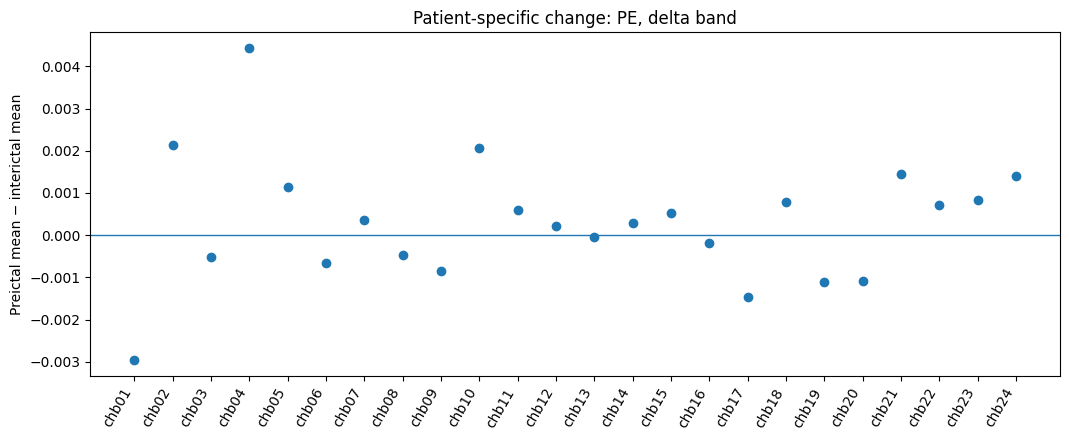

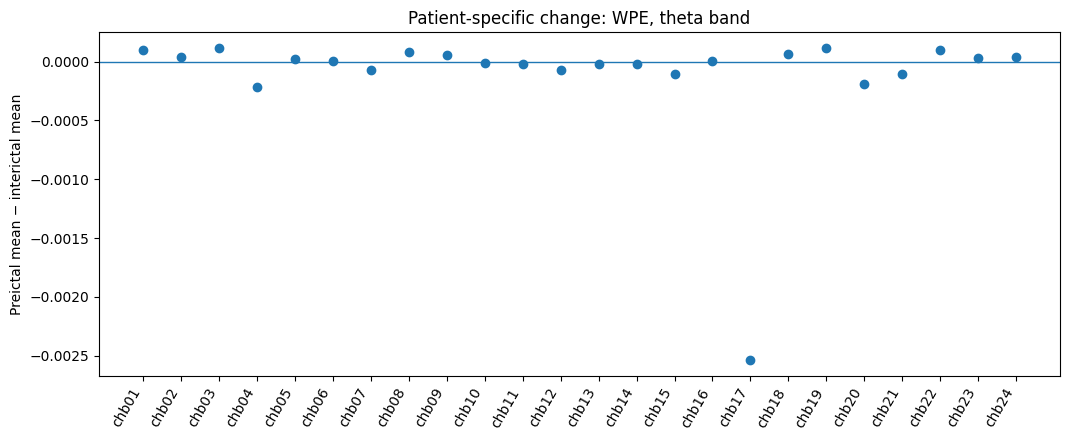

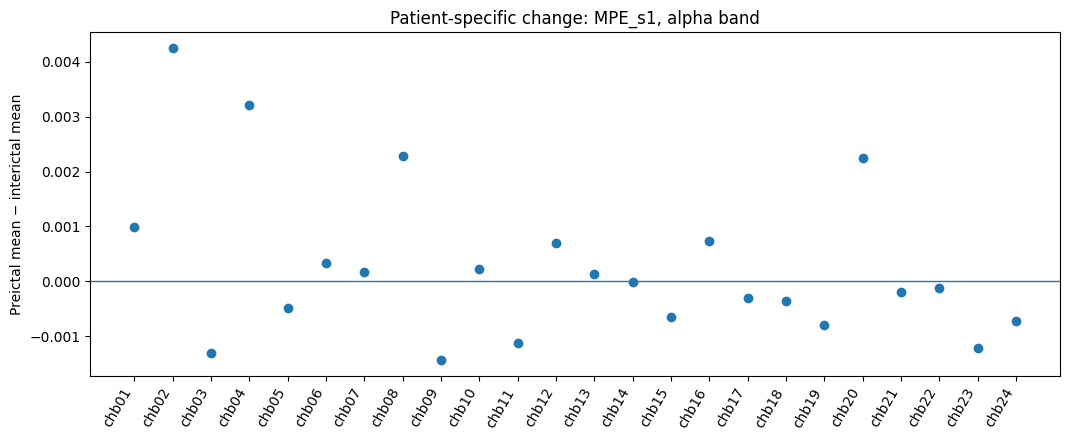

In [ ]:
def plot_interictal_window_trajectory(patient_id, file_name, channel, metric='PE', band='delta'):
    """Plot every interictal window from one seizure-free EDF, without averaging."""
    d=long[(long.patient_id==patient_id)&(long.condition=='interictal')&
           (long.file_name==file_name)&(long.channel==channel)&(long.metric==metric)&(long.band==band)]
    d=d.sort_values('window_mid_sec')
    if d.empty:
        print('No matching interictal windows. Check patient_id, file_name, channel, metric, and band.'); return
    plt.figure(figsize=(12,4.5))
    plt.plot(d.window_mid_sec/60, d.entropy, marker='.', linewidth=0.8)
    plt.xlabel('Time within EDF (minutes)'); plt.ylabel('Entropy')
    plt.title(f'Interictal full-window trajectory | {patient_id} | {channel} | {band} | {metric}')
    plt.grid(True, alpha=.25); plt.tight_layout(); plt.show()

def plot_seizure_window_trajectory(patient_id, seizure_id, channel, metric='PE', band='delta'):
    """Plot every preictal and ictal window around one seizure; x=0 is seizure onset."""
    d=long[(long.patient_id==patient_id)&(long.seizure_id==seizure_id)&
           (long.channel==channel)&(long.metric==metric)&(long.band==band)&
           (long.condition.isin(['preictal','ictal']))].copy()
    d=d.sort_values('relative_to_seizure_onset_sec')
    if d.empty:
        print('No matching seizure trajectory. Inspect long.seizure_id.unique() and available channels.'); return
    x=d.relative_to_seizure_onset_sec/60.0
    plt.figure(figsize=(12,4.5))
    for state in ['preictal','ictal']:
        q=d[d.condition==state]
        if not q.empty:
            plt.plot(q.relative_to_seizure_onset_sec/60.0, q.entropy, marker='.', linewidth=0.8, label=state)
    plt.axvline(0, linestyle='--', linewidth=1, label='seizure onset')
    plt.xlabel('Minutes relative to seizure onset (negative = before onset)'); plt.ylabel('Entropy')
    plt.title(f'Full window trajectory | {patient_id} | {seizure_id} | {channel} | {band} | {metric}')
    plt.grid(True, alpha=.25); plt.legend(); plt.tight_layout(); plt.show()


def plot_cross_patient_individual_trajectories(channel, metric='PE', band='delta', max_patients=24):
    """Overlay individual patients' first available seizure trajectory; no cross-patient averaging.

    Only exact matching channel labels are included. This is a visual shape comparison, not an inferential test.
    """
    d=long[(long.condition.isin(['preictal','ictal']))&(long.channel==channel)&
           (long.metric==metric)&(long.band==band)].copy()
    if d.empty:
        print('No matching seizure-related trajectories for this exact channel label.'); return
    # One seizure per patient for a readable overlay. Choose the first available seizure ID alphabetically.
    chosen=[]
    for pid, g in d.groupby('patient_id'):
        ids=sorted(g.seizure_id.dropna().loc[lambda x:x!=''].unique())
        if ids: chosen.append((pid,ids[0]))
    chosen=chosen[:max_patients]
    plt.figure(figsize=(12,5))
    plotted=0
    for pid,sid in chosen:
        q=d[(d.patient_id==pid)&(d.seizure_id==sid)].sort_values('relative_to_seizure_onset_sec')
        if q.empty: continue
        # Plot every window as a separate patient's line; no averaging or smoothing.
        plt.plot(q.relative_to_seizure_onset_sec/60.0, q.entropy, marker='.', linewidth=0.8, alpha=.8, label=f'{pid}')
        plotted+=1
    plt.axvline(0, linestyle='--', linewidth=1, color='black')
    plt.xlabel('Minutes relative to seizure onset (negative = before onset)'); plt.ylabel('Entropy')
    plt.title(f'Cross-patient individual trajectories (n={plotted}) | {channel} | {band} | {metric}')
    if plotted <= 12: plt.legend(fontsize=8, ncol=2)
    plt.grid(True, alpha=.25); plt.tight_layout(); plt.show()

print('Patients:', sorted(long.patient_id.dropna().unique()))
print('Example seizure IDs:')
display(long.loc[long.seizure_id.ne(''), ['patient_id','file_name','seizure_id']].drop_duplicates().head(20))
print("Example calls after processing:")
print("plot_interictal_window_trajectory('chb01', 'chb01_01.edf', 'FP1-F7', metric='PE', band='theta')")
print("plot_seizure_window_trajectory('chb01', '<copy exact seizure_id above>', 'FP1-F7', metric='PE', band='theta')")
print("plot_cross_patient_individual_trajectories('FP1-F7', metric='PE', band='theta')")

## 9. Cross-patient comparison without replacing trajectories by averages

The primary cross-patient comparison is an overlay of individual seizure-relative window trajectories (see `plot_cross_patient_individual_trajectories`). Each line is one patient's seizure trajectory and every point is one overlapping window. Use exact common channel labels only after harmonizing channel names/montages. Patients may have different seizure durations and available preictal windows, so do not interpolate missing windows or interpret absent regions as zero.

The optional patient-state summary can describe group-level differences, but it must remain secondary. For formal inference, use patient-/seizure-aware methods and account for repeated measures, correlated overlapping windows, and multiple testing.

In [ ]:
# Optional state-level descriptive table only; this is not used to build or plot the raw trajectories.
cross_state=(patient_state.groupby(['band','metric','condition'])
 .agg(n_patients=('patient_id','nunique'),mean_of_patient_means=('mean_entropy','mean'),
      median_of_patient_medians=('median_entropy','median'),sd_of_patient_means=('mean_entropy','std')).reset_index())
cross_state.to_csv(OUTPUT_DIR/'optional_cross_patient_state_summary.csv', index=False)
display(cross_state)
print('Primary trajectory files remain window-level and unaveraged.')

,band,metric,direction,n_patients
0,alpha,MPE_s1,decrease,13
1,alpha,MPE_s1,increase,11
2,alpha,MPE_s2,decrease,12
3,alpha,MPE_s2,increase,12
4,alpha,MPE_s3,decrease,13
5,alpha,MPE_s3,increase,11
6,alpha,MPE_s4,decrease,13
7,alpha,MPE_s4,increase,11
8,alpha,MPE_s5,decrease,13
9,alpha,MPE_s5,increase,11


,band,metric,n_patients,median_delta,mean_delta,sd_delta
0,alpha,MPE_s1,24,-0.000065,0.000272,0.001443
1,alpha,MPE_s2,24,0.000124,0.000455,0.002159
2,alpha,MPE_s3,24,-0.000110,0.000422,0.002549
3,alpha,MPE_s4,24,-0.000119,0.000445,0.002680
4,alpha,MPE_s5,24,-0.000093,0.000449,0.002536
5,alpha,PE,24,-0.000065,0.000272,0.001443
6,alpha,WPE,24,-0.000052,0.000025,0.000244
7,delta,MPE_s1,24,0.000319,0.000317,0.001463
8,delta,MPE_s2,24,0.000578,0.000564,0.002412
9,delta,MPE_s3,24,0.000836,0.000754,0.003206


,band,metric,n_paired_patients,median_patient_delta,wilcoxon_statistic,p_value_uncorrected
0,alpha,MPE_s1,24,-0.000065,147.0,0.944107
1,alpha,MPE_s2,24,0.000124,137.0,0.725741
2,alpha,MPE_s3,24,-0.000110,149.0,0.988813
3,alpha,MPE_s4,24,-0.000119,148.0,0.966447
4,alpha,MPE_s5,24,-0.000093,149.0,0.988813
5,alpha,PE,24,-0.000065,147.0,0.944107
6,alpha,WPE,24,-0.000052,141.0,0.811536
7,delta,MPE_s1,24,0.000319,114.0,0.316512
8,delta,MPE_s2,24,0.000578,112.0,0.289667
9,delta,MPE_s3,24,0.000836,111.0,0.276815


P-values are uncorrected and exploratory; apply an appropriate multiple-testing correction before interpretation.


## 10. Output files and validation checklist

Saved under `My Drive/chbmit/entropy_frequency_band_results_overlapping_allbands_v3`:
- `entropy_features_channel_window_band.csv`: every channel × overlapping window × band, with PE/WPE/MPE values.
- `window_level_entropy_trajectories.csv`: **primary long-format file**; every window is retained separately for each entropy metric.
- `full_preictal_ictal_window_trajectories.csv`: every preictal and ictal window, keyed by patient and seizure.
- `full_interictal_window_trajectories.csv`: every interictal window in EDF-local time.
- `optional_patient_state_summary.csv`, `optional_patient_channel_state_summary.csv`, `optional_cross_patient_state_summary.csv`: optional summaries only, not substitutes for trajectories.
- `processing_manifest.csv`, `per_edf/`, and `channel_band_checkpoints/` support resuming after interruptions.

Before publication, validate seizure annotations, montage/channel consistency, interictal EDF eligibility, number of windows per state, filtering and artifact sensitivity. Overlapping windows are correlated; do not treat them as independent samples.

In [ ]:
print('Output folder:', OUTPUT_DIR)
print('Window-level feature rows:', len(features), '| patients:', features.patient_id.nunique())
print('Bands:', list(BANDS), '| window/step:', WINDOW_SECONDS, '/', STEP_SECONDS, 'seconds')
print('States present:', sorted(features.condition.dropna().unique()))
print('Primary output: window_level_entropy_trajectories.csv (all windows preserved; no averaging).')
print('If interrupted, rerun setup/discovery/parser cells and processing; saved channel-band chunks are reused.')

Output folder: /content/drive/MyDrive/chbmit/entropy_frequency_band_results
Feature rows: 23795004 | patients: 24
